In [1]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt, colors, patches

from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), '../../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/data_exploration/../import/utils/train_utils.py'>

In [3]:
selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 3

plot_id = 19

In [4]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_data(path)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# remove unused discrete state labels
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [5]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_plsc_man, loads_plsc_man_b,
 vars_expl_mans) = train_utils.get_manifolds_plsc(traces,
												  [ds[selection_bhl] for ds in discrete_states],
												  n_ls=dims)

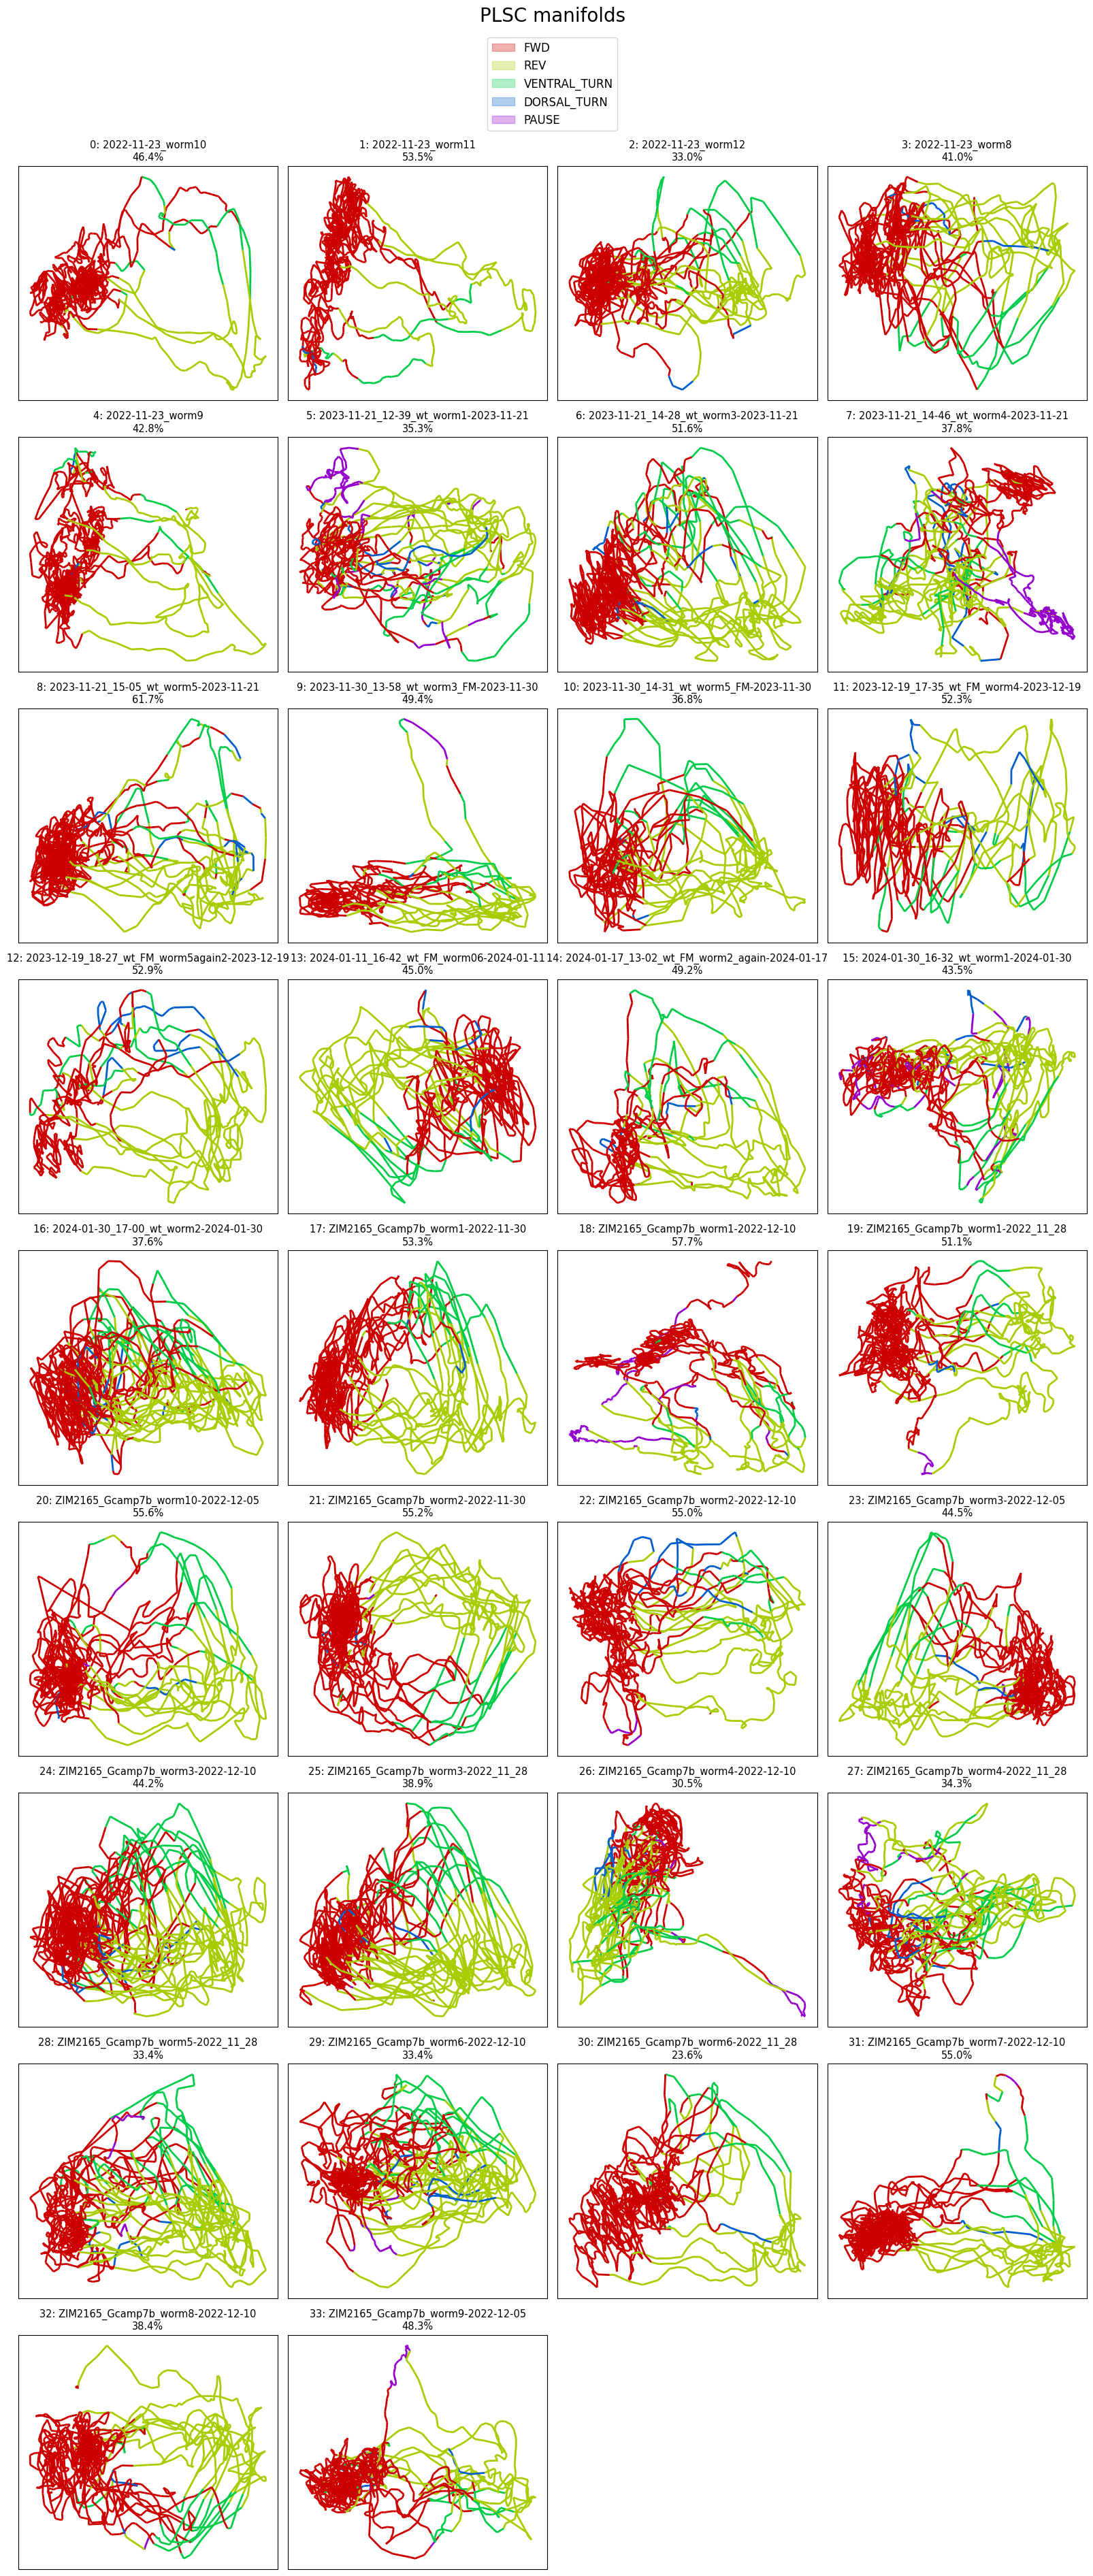

44.8%


In [6]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PLSC manifolds', save_name=f'{dims}-dim-PLSC')

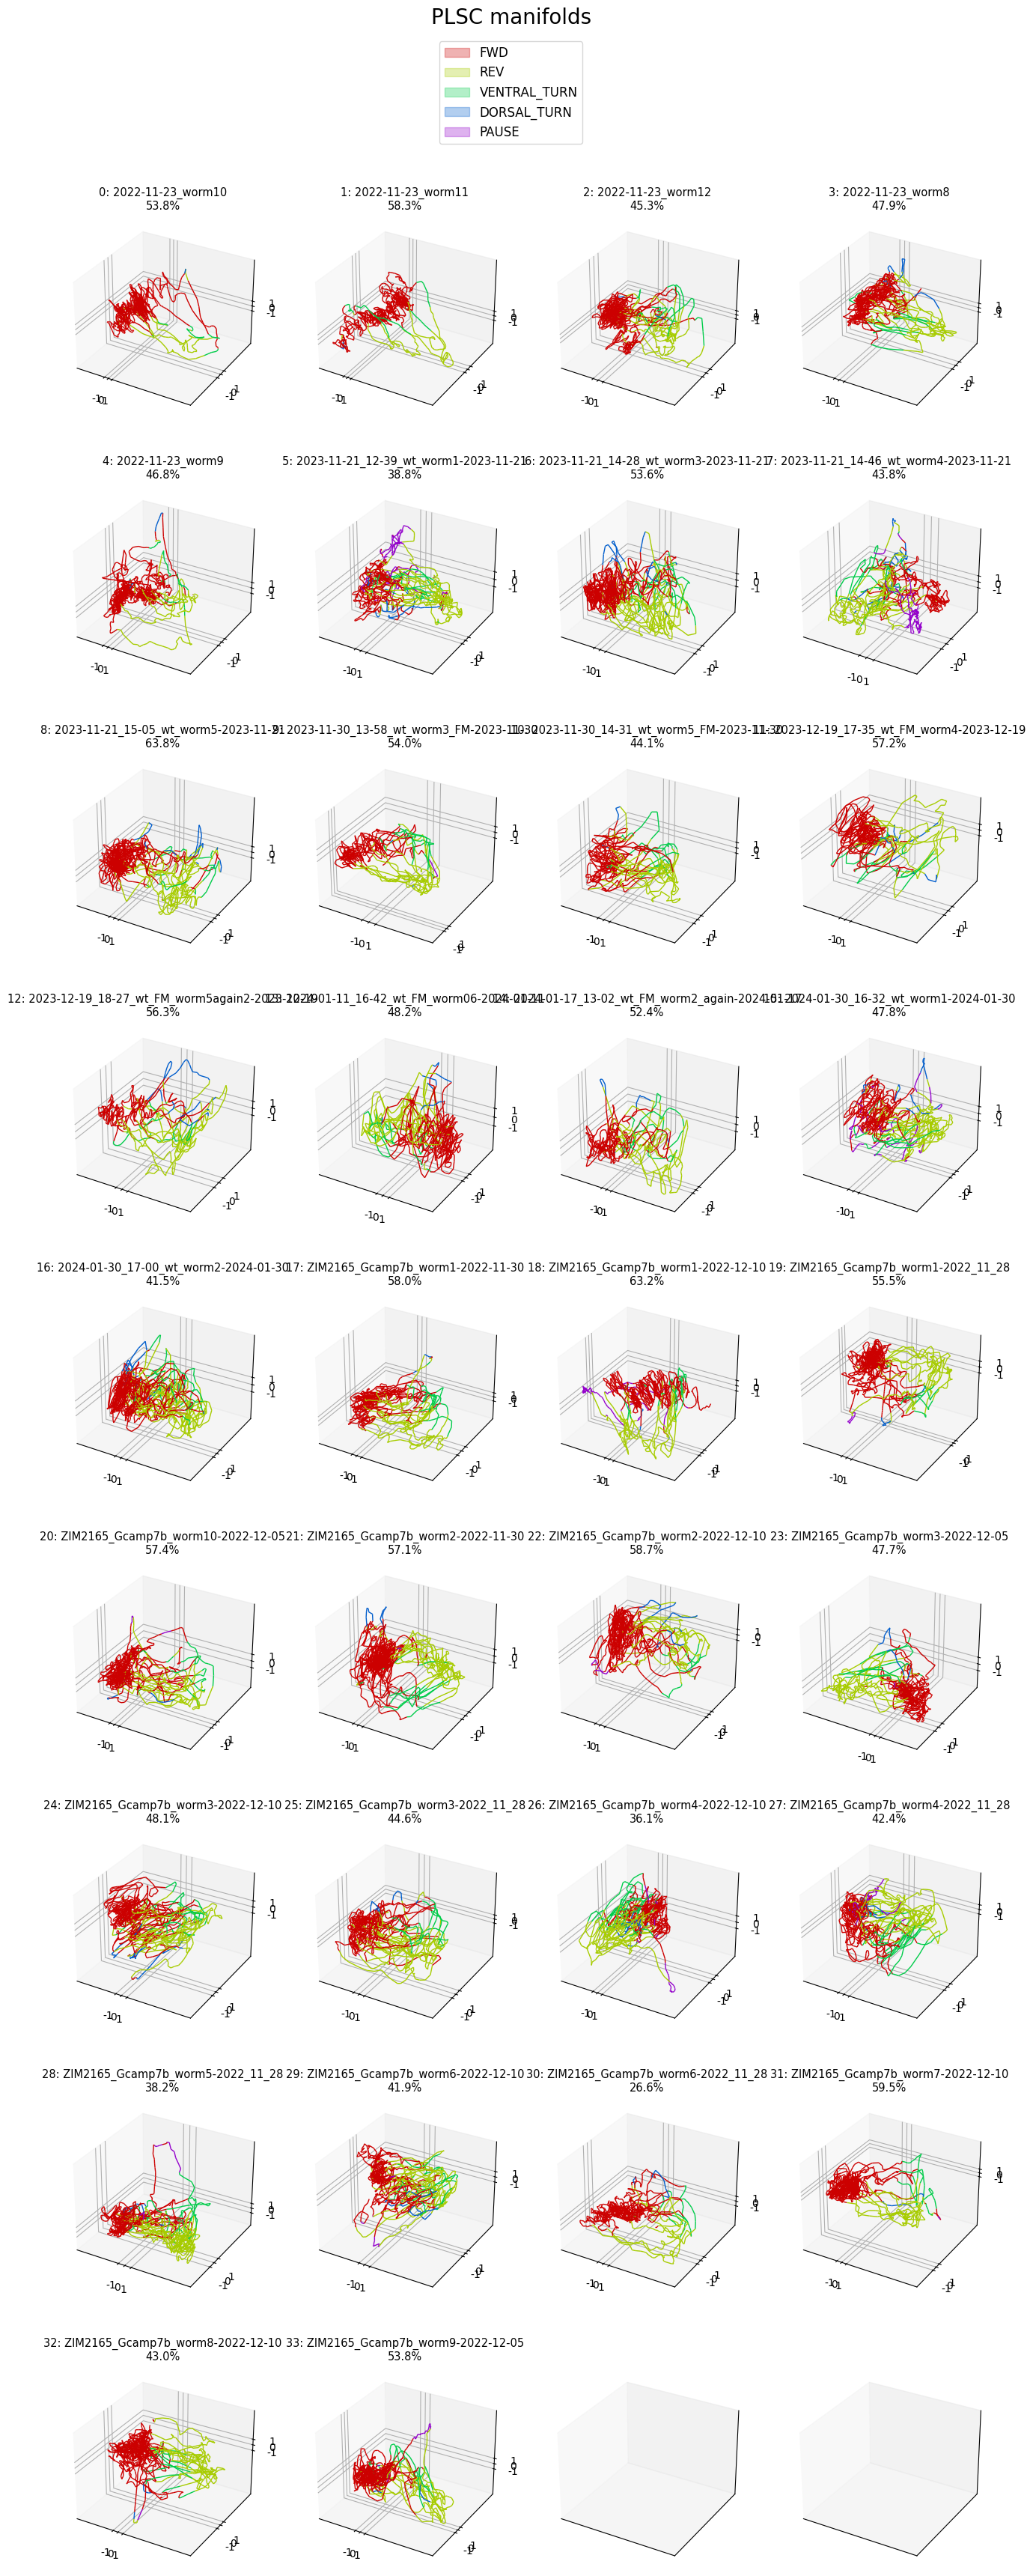

49.6%


In [7]:
plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
							 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
							 [vx[:3] for vx in vars_expl_mans], None,
							 title='PLSC manifolds', save_name=f'{dims}-dim-PLSC')

In [ ]:
plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
								 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
								 [vx[:3] for vx in vars_expl_mans], None,
								 animate=True, n_plots=1,
								 titles=['PLSC manifolds'] * len(file_ids), save_name=f'{dims}-dim-PLSC')

In [ ]:
# traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recos_manifold)]
#
# plot_utils.plot_traces('residuals',
# 					   discrete_states[file_ids.index(plot_id)]['REV'],
# 					   traces_residual[file_ids.index(plot_id)][selection_n],
# 					   n_plots=None, plots_per_row=1, ylimits=None)